release_year
2014     352
2015     555
2016     901
2017    1030
2018    1146
2019    1030
2020     953
2021     592
Name: titles, dtype: int64


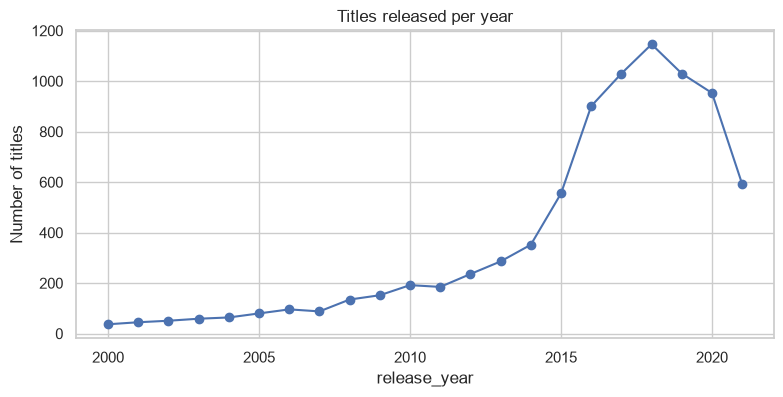

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

CLEAN_PATH = Path("../data/processed/netflix_clean.csv")
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(CLEAN_PATH, parse_dates=["date_added"])

# Titles released per year (release_year), 2000 onwards to avoid very sparse early years
yearly = (
    df[df["release_year"] >= 2000]
    .groupby("release_year")
    .size()
    .rename("titles")
)
print(yearly.tail(8))
yearly.plot(marker="o", figsize=(9, 4), title="Titles released per year")
plt.ylabel("Number of titles")
plt.show()

,titles,yoy_change_%,rolling_3yr_avg
release_year,,,
2011,185,-3.6,176.3
2012,236,27.6,204.3
2013,286,21.2,235.7
2014,352,23.1,291.3
2015,555,57.7,397.7
2016,901,62.3,602.7
2017,1030,14.3,828.7
2018,1146,11.3,1025.7
2019,1030,-10.1,1068.7


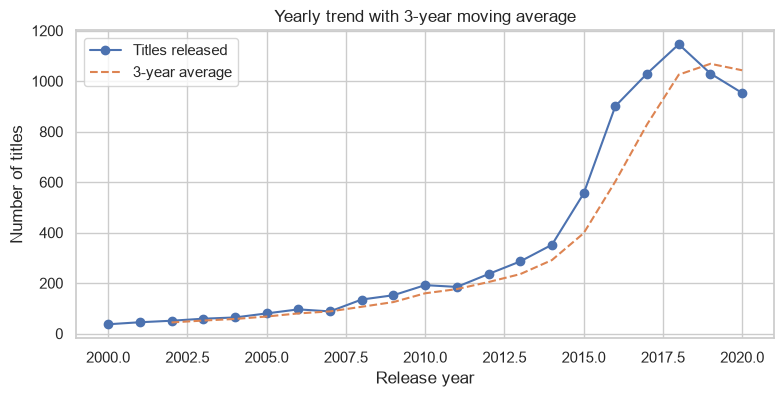

In [2]:
# Drop 2021: the year is incomplete (data ends in September 2021)
series = yearly[yearly.index <= 2020].copy()

trend = pd.DataFrame({
    "titles": series,
    "yoy_change_%": (series.pct_change() * 100).round(1),
    "rolling_3yr_avg": series.rolling(3).mean().round(1),
})
display(trend.tail(10))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(series.index, series.values, marker="o", label="Titles released")
ax.plot(trend.index, trend["rolling_3yr_avg"], linestyle="--", label="3-year average")
ax.set_title("Yearly trend with 3-year moving average")
ax.set_xlabel("Release year")
ax.set_ylabel("Number of titles")
ax.legend()
plt.show()

In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing

train = series[series.index <= 2016]
test = series[series.index > 2016]

# Model 1: linear regression on year
lr = LinearRegression().fit(train.index.to_frame(), train.values)
lr_pred = lr.predict(test.index.to_frame())

# Model 2: Holt's exponential smoothing (trend, no seasonality for yearly data)
hw = ExponentialSmoothing(train.values.astype(float), trend="add").fit()
hw_pred = hw.forecast(len(test))

results = pd.DataFrame({
    "Model": ["Linear Regression", "Holt (Exp. Smoothing)"],
    "MAE": [mean_absolute_error(test, lr_pred), mean_absolute_error(test, hw_pred)],
    "RMSE": [np.sqrt(mean_squared_error(test, lr_pred)),
             np.sqrt(mean_squared_error(test, hw_pred))],
}).round(1)
display(results)

comparison = pd.DataFrame({"actual": test, "linear": lr_pred.round(0), "holt": hw_pred.round(0)})
display(comparison)

,Model,MAE,RMSE
0,Linear Regression,455.2,465.5
1,Holt (Exp. Smoothing),726.2,843.7


,actual,linear,holt
release_year,,,
2017,1030,531.0,1247.0
2018,1146,567.0,1593.0
2019,1030,603.0,1939.0
2020,953,639.0,2285.0


,full_history,recent_2015_2020
year,,
2021,977.0,1185.0
2022,1033.0,1256.0
2023,1089.0,1328.0
2024,1144.0,1399.0
2025,1200.0,1470.0


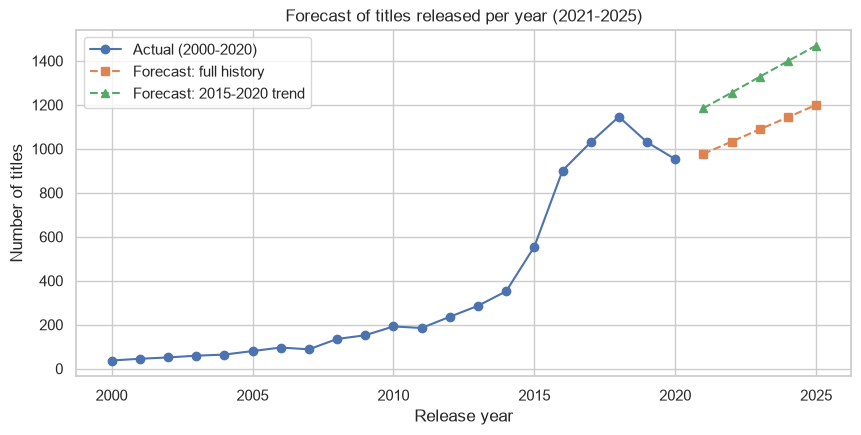

In [6]:
# Fit on the full series (2000-2020) and on the recent period only (2015-2020)
future_years = pd.DataFrame({"release_year": range(2021, 2026)})

lr_full = LinearRegression().fit(series.index.to_frame(), series.values)
recent = series[series.index >= 2015]
lr_recent = LinearRegression().fit(recent.index.to_frame(), recent.values)

forecast = pd.DataFrame({
    "year": future_years["release_year"],
    "full_history": lr_full.predict(future_years).round(0),
    "recent_2015_2020": lr_recent.predict(future_years).round(0),
}).set_index("year")
display(forecast)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(series.index, series.values, marker="o", label="Actual (2000-2020)")
ax.plot(forecast.index, forecast["full_history"], "--", marker="s", label="Forecast: full history")
ax.plot(forecast.index, forecast["recent_2015_2020"], "--", marker="^", label="Forecast: 2015-2020 trend")
ax.set_title("Forecast of titles released per year (2021-2025)")
ax.set_xlabel("Release year")
ax.set_ylabel("Number of titles")
ax.legend()
fig.savefig(FIG_DIR / "trend_forecast.png", dpi=150, bbox_inches="tight")
plt.show()

## Summary and Interpretation

**Data:** titles per `release_year`, 2000-2020. 2021 was excluded because the dataset ends in September 2021 (incomplete year).

**Trend:** output stayed low until about 2014, grew sharply from 2015, peaked in **2018 (1,146 titles)**, then declined slightly in 2019 (1,030) and 2020 (953).

**Models (train 2000-2016, test 2017-2020):**

| Model | MAE | RMSE |
|---|---|---|
| Linear Regression | 455.2 | 465.5 |
| Holt (Exponential Smoothing) | 726.2 | 843.7 |

Linear Regression had the lower error. Both models missed in different directions: Holt overshot badly (it extrapolated the 2015-2016 surge), while Linear Regression undershot (it was fitted mostly on the low early years).

**Forecast 2021-2025:** both linear fits point upward. The full-history model gives 977 titles in 2021 rising to 1,200 in 2025, and the 2015-2020 model gives 1,185 rising to 1,470. These forecasts should be treated with caution: the actual data has been *falling* since the 2018 peak (1,146 to 953 by 2020), so a straight line, which ignores this peak and decline, probably overestimates future output.

**Limitations:** only 21 yearly data points; a linear model cannot represent a rise followed by a decline; `release_year` is not the same as Netflix catalogue growth; and outside factors (e.g. the 2020 pandemic) are not modelled. Forecasts are indicative only.